In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install timm facenet-pytorch opencv-python tqdm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'Pillow' when getting requirements to build wheel


In [ ]:
!pip install timm opencv-python tqdm pillow
!pip install facenet-pytorch --no-deps

  Using cached facenet_pytorch-2.6.0-py3-none-any.whl.metadata (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 7.9 MB/s  0:00:00


In [ ]:
import torch
from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
print("Setup successful!")

Setup successful!


In [ ]:
code = '''# -*- coding: utf-8 -*-
import argparse, os, urllib.request, tempfile, time, sys, json
from tqdm import tqdm
from os.path import join

FILELIST_URL = 'misc/filelist.json'
DEEPFEAKES_DETECTION_URL = 'misc/deepfake_detection_filenames.json'

DATASETS = {
    'original': 'original_sequences/youtube',
    'Deepfakes': 'manipulated_sequences/Deepfakes',
}
COMPRESSION = ['raw', 'c23', 'c40']
SERVERS = ['EU', 'EU2', 'CA']

def parse_args():
    parser = argparse.ArgumentParser()
    parser.add_argument('output_path', type=str)
    parser.add_argument('-d', '--dataset', type=str, default='original', choices=list(DATASETS.keys()))
    parser.add_argument('-c', '--compression', type=str, default='c23', choices=COMPRESSION)
    parser.add_argument('-t', '--type', type=str, default='videos')
    parser.add_argument('-n', '--num_videos', type=int, default=100)
    parser.add_argument('--server', type=str, default='EU', choices=SERVERS)
    args = parser.parse_args()

    server_urls = {
        'EU': 'http://canis.vc.in.tum.de:8100/',
        'EU2': 'http://kaldir.vc.in.tum.de/faceforensics/',
        'CA': 'http://falas.cmpt.sfu.ca:8100/'
    }
    args.base_url = server_urls[args.server] + 'v3/'
    return args

def download_file(url, out_file):
    os.makedirs(os.path.dirname(out_file), exist_ok=True)
    if not os.path.isfile(out_file):
        fh, tmp = tempfile.mkstemp(dir=os.path.dirname(out_file))
        os.close(fh)
        urllib.request.urlretrieve(url, tmp)
        os.rename(tmp, out_file)

def main(args):
    dataset_path = DATASETS[args.dataset]
    print(f"Downloading {args.num_videos} videos from {args.dataset} ({args.compression})...")

    file_pairs = json.loads(urllib.request.urlopen(args.base_url + FILELIST_URL).read().decode("utf-8"))
    if args.dataset == 'original':
        filelist = [item for pair in file_pairs for item in pair]
    else:
        filelist = ['_'.join(pair) for pair in file_pairs]

    if args.num_videos:
        filelist = filelist[:args.num_videos]

    base_video_url = args.base_url + f"{dataset_path}/{args.compression}/{args.type}/"
    out_dir = join(args.output_path, dataset_path, args.compression, args.type)
    os.makedirs(out_dir, exist_ok=True)

    for fn in tqdm(filelist):
        download_file(base_video_url + fn + '.mp4', join(out_dir, fn + '.mp4'))
    print(f"Done! Saved to {out_dir}")

if __name__ == '__main__':
    main(parse_args())
'''

with open("download_ff.py", "w") as f:
    f.write(code)

In [ ]:
# Try EU2 first
!python download_ff.py /content/ff_data -d original -c c23 -n 100 --server EU2
!python download_ff.py /content/ff_data -d Deepfakes -c c23 -n 100 --server EU2

100% 100/100 [03:09<00:00,  1.89s/it]
Done! Saved to /content/ff_data/original_sequences/youtube/c23/videos
100% 100/100 [03:12<00:00,  1.93s/it]
Done! Saved to /content/ff_data/manipulated_sequences/Deepfakes/c23/videos


In [ ]:
import os, cv2, torch, numpy as np
from PIL import Image
from facenet_pytorch import MTCNN
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
mtcnn = MTCNN(keep_all=False, post_process=False, select_largest=True, device=device)

def process_video_folder(in_dir, out_dir, num_frames=32):
    os.makedirs(out_dir, exist_ok=True)
    videos = [f for f in os.listdir(in_dir) if f.endswith('.mp4')]

    for vid_name in tqdm(videos):
        vid_id = os.path.splitext(vid_name)[0]
        cap = cv2.VideoCapture(os.path.join(in_dir, vid_name))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total <= 0:
            cap.release()
            continue

        indices = np.linspace(0, total - 1, num_frames).astype(int)
        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, frame = cap.read()
            if not ok: continue

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            pil_img = Image.fromarray(rgb)
            boxes, probs = mtcnn.detect(pil_img)
            if boxes is None or len(boxes) == 0: continue

            x1, y1, x2, y2 = boxes[0]
            margin = 0.3 * max(x2 - x1, y2 - y1)
            x1 = max(0, int(x1 - margin))
            y1 = max(0, int(y1 - margin))
            x2 = min(rgb.shape[1], int(x2 + margin))
            y2 = min(rgb.shape[0], int(y2 + margin))

            crop = pil_img.crop((x1, y1, x2, y2)).resize((224, 224), Image.BILINEAR)
            crop.save(os.path.join(out_dir, f"{vid_id}_f{idx:04d}.png"))
        cap.release()

# Split 70 train, 15 val, 15 test
for label, in_path in [
    ("real", "/content/ff_data/original_sequences/youtube/c23/videos"),
    ("fake", "/content/ff_data/manipulated_sequences/Deepfakes/c23/videos")
]:
    vids = sorted([f for f in os.listdir(in_path) if f.endswith('.mp4')])
    splits = {
        "train": vids[:70],
        "val": vids[70:85],
        "test": vids[85:100]
    }
    for split_name, split_vids in splits.items():
        out_folder = f"/content/dataset/{split_name}/{label}"
        os.makedirs(out_folder, exist_ok=True)
        # Process each video list
        print(f"Extracting {split_name}/{label}...")
        for v in tqdm(split_vids):
            # Process individual video
            cap = cv2.VideoCapture(os.path.join(in_path, v))
            total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            if total <= 0:
                cap.release()
                continue
            indices = np.linspace(0, total - 1, 24).astype(int)
            for idx in indices:
                cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
                ok, frame = cap.read()
                if not ok: continue
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                pil_img = Image.fromarray(rgb)
                boxes, _ = mtcnn.detect(pil_img)
                if boxes is None or len(boxes) == 0: continue
                x1, y1, x2, y2 = boxes[0]
                margin = 0.3 * max(x2 - x1, y2 - y1)
                x1, y1 = max(0, int(x1 - margin)), max(0, int(y1 - margin))
                x2, y2 = min(rgb.shape[1], int(x2 + margin)), min(rgb.shape[0], int(y2 + margin))
                crop = pil_img.crop((x1, y1, x2, y2)).resize((224, 224), Image.BILINEAR)
                crop.save(os.path.join(out_folder, f"{os.path.splitext(v)[0]}_f{idx:04d}.png"))
            cap.release()

Extracting train/real...


100%|██████████| 70/70 [10:56<00:00,  9.37s/it]


Extracting val/real...


100%|██████████| 15/15 [03:21<00:00, 13.46s/it]


Extracting test/real...


100%|██████████| 15/15 [02:51<00:00, 11.46s/it]


... (2 outputs left out)

Extracting val/fake...


100%|██████████| 15/15 [04:03<00:00, 16.26s/it]


Extracting test/fake...


100%|██████████| 15/15 [02:36<00:00, 10.43s/it]


In [ ]:
import os
for split in ['train', 'val', 'test']:
    for label in ['real', 'fake']:
        path = f'/content/dataset/{split}/{label}'
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        print(f"{split}/{label}: {count} faces")

train/real: 1680 faces
train/fake: 1680 faces
val/real: 360 faces
val/fake: 360 faces
test/real: 360 faces
test/fake: 360 faces


In [ ]:
import torch, timm, copy, time
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# 1. Image Augmentations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.ColorJitter(0.2, 0.2, 0.1)], p=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Data Loaders
train_set = datasets.ImageFolder("/content/dataset/train", train_transform)
val_set   = datasets.ImageFolder("/content/dataset/val", eval_transform)
test_set  = datasets.ImageFolder("/content/dataset/test", eval_transform)

print(f"Classes: {train_set.classes}")  # ['fake', 'real'] -> fake=0, real=1
print(f"Total: Train={len(train_set)} | Val={len(val_set)} | Test={len(test_set)}")

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

# 3. Model setup (Pretrained EfficientNet-B0)
model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# 4. Training Loop (8 epochs is ideal)
best_val_acc = 0.0
best_weights = None

print("\nStarting Training...")
print("-" * 55)

for epoch in range(8):
    t0 = time.time()

    # Train Phase
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outs = model(imgs)
        loss = criterion(outs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
        train_correct += (outs.argmax(1) == labels).sum().item()
        train_total += imgs.size(0)

    # Validation Phase
    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outs = model(imgs)
            val_correct += (outs.argmax(1) == labels).sum().item()
            val_total += imgs.size(0)

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total
    elapsed = time.time() - t0

    star = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())
        star = " ★ (best)"

    print(f"Epoch {epoch+1}/8 | Train Loss: {train_loss/train_total:.4f} | "
          f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | {elapsed:.0f}s{star}")

# 5. Evaluate on Test Set
print("\n" + "=" * 55)
print("TEST SET EVALUATION")
print("=" * 55)
model.load_state_dict(best_weights)
model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outs = model(imgs)
        y_true.extend(labels.numpy())
        y_pred.extend(outs.argmax(1).cpu().numpy())

print(classification_report(y_true, y_pred, target_names=test_set.classes))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

# 6. Save Weights to Google Drive and local Colab runtime
torch.save(best_weights, "/content/video_clf.pth")
try:
    torch.save(best_weights, "/content/drive/MyDrive/video_clf.pth")
    print("\n✅ Saved to Google Drive: MyDrive/video_clf.pth")
except Exception as e:
    print("\n(Google Drive not mounted, saved to /content/video_clf.pth)")

Training on device: cuda
Classes: ['fake', 'real']
Total: Train=3360 | Val=720 | Test=720


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            


Starting Training...
-------------------------------------------------------
Epoch 1/8 | Train Loss: 0.4149 | Train Acc: 0.8890 | Val Acc: 0.7403 | 24s ★ (best)
Epoch 2/8 | Train Loss: 0.0533 | Train Acc: 0.9818 | Val Acc: 0.8042 | 22s ★ (best)
Epoch 3/8 | Train Loss: 0.0285 | Train Acc: 0.9932 | Val Acc: 0.8194 | 23s ★ (best)
Epoch 4/8 | Train Loss: 0.0238 | Train Acc: 0.9917 | Val Acc: 0.8250 | 22s ★ (best)
Epoch 5/8 | Train Loss: 0.0299 | Train Acc: 0.9914 | Val Acc: 0.8431 | 24s ★ (best)
Epoch 6/8 | Train Loss: 0.0281 | Train Acc: 0.9923 | Val Acc: 0.8181 | 22s
Epoch 7/8 | Train Loss: 0.0073 | Train Acc: 0.9970 | Val Acc: 0.7944 | 23s
Epoch 8/8 | Train Loss: 0.0082 | Train Acc: 0.9967 | Val Acc: 0.8181 | 22s

TEST SET EVALUATION
              precision    recall  f1-score   support

        fake       0.95      0.67      0.78       360
        real       0.74      0.97      0.84       360

    accuracy                           0.82       720
   macro avg       0.85      0.82     

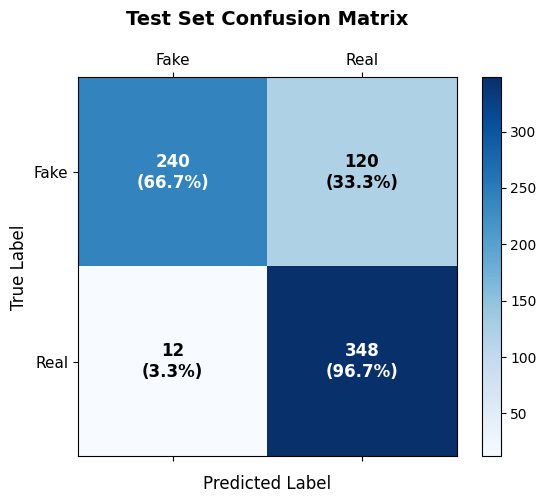

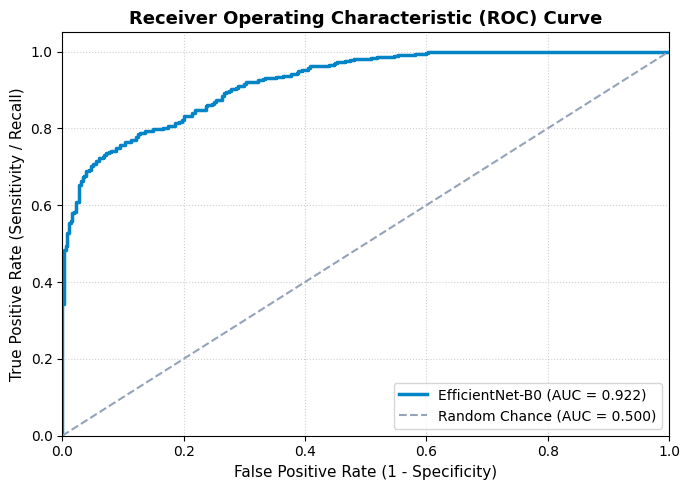

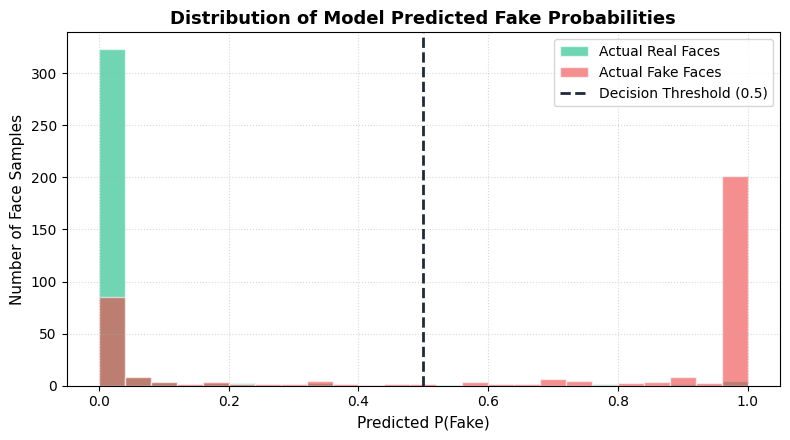

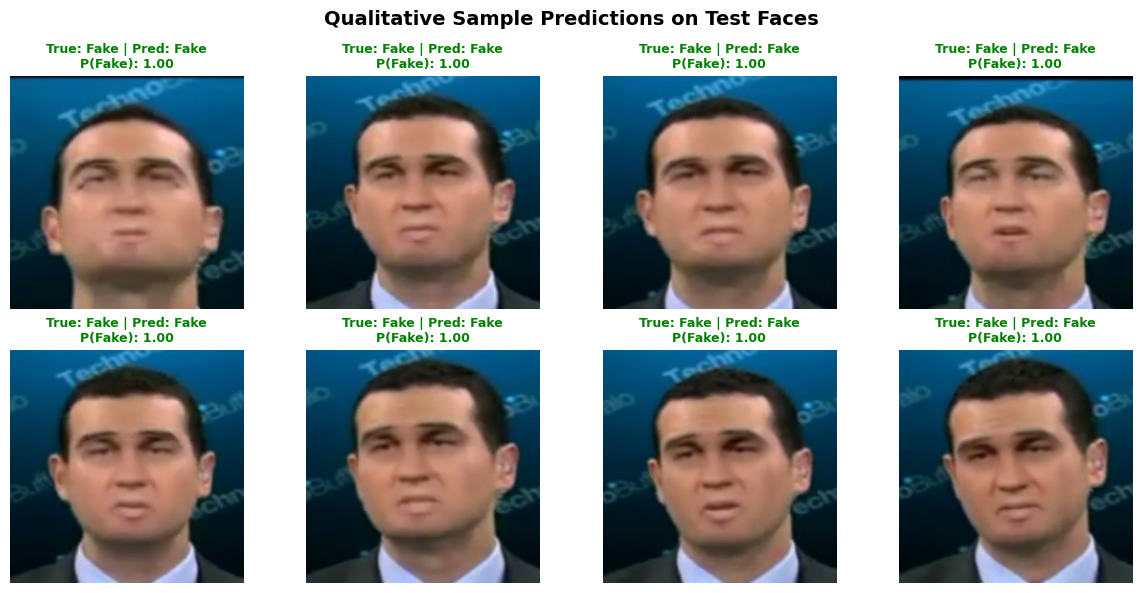


✅ All 4 high-res figures generated and saved to your Google Drive!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay

# Ensure model is in eval mode
model.eval()

# 1. Collect all probabilities and labels from test set
all_probs = []
all_targets = []
all_sample_imgs = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outs = model(imgs)
        probs = torch.softmax(outs, dim=1)

        # Class 0 = fake, Class 1 = real
        all_probs.extend(probs[:, 0].cpu().numpy())  # P(Fake)
        all_targets.extend(labels.numpy())
        if len(all_sample_imgs) < 16:
            all_sample_imgs.extend(imgs.cpu())

all_probs = np.array(all_probs)
all_targets = np.array(all_targets)
# For ROC: 1 = fake, 0 = real
y_true_binary = (all_targets == 0).astype(int)

# ==========================================
# GRAPH 1: Confusion Matrix with Counts & %
# ==========================================
cm = confusion_matrix(all_targets, (all_probs < 0.5).astype(int))
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap='Blues')
plt.title('Test Set Confusion Matrix', pad=20, fontsize=14, fontweight='bold')
fig.colorbar(cax)

labels = ['Fake', 'Real']
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(labels, fontsize=11)
ax.set_yticklabels(labels, fontsize=11)
plt.xlabel('Predicted Label', labelpad=10, fontsize=12)
plt.ylabel('True Label', fontsize=12)

for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max()/2 else "black"
        ax.text(j, i, f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)",
                ha="center", va="center", color=color, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig1_confusion_matrix.png', dpi=300)
plt.show()

# ==========================================
# GRAPH 2: ROC Curve & AUC Score
# ==========================================
fpr, tpr, _ = roc_curve(y_true_binary, all_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#0284c7', lw=2.5, label=f'EfficientNet-B0 (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='#94a3b8', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=13, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig2_roc_curve.png', dpi=300)
plt.show()

# ==========================================
# GRAPH 3: Probability Score Distribution
# ==========================================
plt.figure(figsize=(8, 4.5))
fake_scores = all_probs[y_true_binary == 1]
real_scores = all_probs[y_true_binary == 0]

plt.hist(real_scores, bins=25, alpha=0.6, color='#10b981', label='Actual Real Faces', edgecolor='white')
plt.hist(fake_scores, bins=25, alpha=0.6, color='#ef4444', label='Actual Fake Faces', edgecolor='white')
plt.axvline(0.5, color='#1e293b', linestyle='--', linewidth=2, label='Decision Threshold (0.5)')

plt.title('Distribution of Model Predicted Fake Probabilities', fontsize=13, fontweight='bold')
plt.xlabel('Predicted P(Fake)', fontsize=11)
plt.ylabel('Number of Face Samples', fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig3_score_distribution.png', dpi=300)
plt.show()

# ==========================================
# GRAPH 4: Visual Qualitative Predictions Grid
# ==========================================
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for idx, ax in enumerate(axes.flat):
    img = all_sample_imgs[idx].permute(1, 2, 0).numpy()
    img = np.clip(img * std + mean, 0, 1)

    true_cls = "Fake" if y_true_binary[idx] == 1 else "Real"
    prob_fake = all_probs[idx]
    pred_cls = "Fake" if prob_fake >= 0.5 else "Real"

    is_correct = (true_cls == pred_cls)
    color = "green" if is_correct else "red"

    ax.imshow(img)
    ax.set_title(f"True: {true_cls} | Pred: {pred_cls}\nP(Fake): {prob_fake:.2f}",
                 fontsize=9, color=color, fontweight='bold')
    ax.axis('off')

plt.suptitle('Qualitative Sample Predictions on Test Faces', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig4_sample_predictions.png', dpi=300)
plt.show()

print("\n✅ All 4 high-res figures generated and saved to your Google Drive!")